In [1]:

# Thiranex Internship Project
# Data Cleaning and Visualization

print("Thiranex Internship: Data Cleaning and Visualization")
print("Project started successfully!")


Thiranex Internship: Data Cleaning and Visualization
Project started successfully!


In [2]:

# Step 1: Import the libraries needed for our project

import pandas as pd
import matplotlib.pyplot as plt

print("Pandas version:", pd.__version__)
print("Libraries imported successfully!")


Pandas version: 2.2.3
Libraries imported successfully!


In [3]:

# Step 2: Create our sample raw dataset

import pandas as pd

data = {
    "Student": [
        "Asha", "Rahul", "Meera", "Arjun", "Diya",
        "Kiran", "Neha", "Rohan", "Anu", "Vijay",
        "Asha", "Priya", "Joel", "Sara", "Manu"
    ],
    "Study_Hours": [
        2, 4, 3, 5, None,
        6, 2, 4, 3, 5,
        2, 7, 4, 3, 100
    ],
    "Attendance": [
        75, 85, 80, 90, 88,
        None, 70, 95, 82, 85,
        75, 92, 78, 89, 80
    ],
    "Exam_Score": [
        55, 75, 65, 88, 72,
        90, 50, 95, None, 80,
        55, 98, 68, 85, 45
    ]
}

df = pd.DataFrame(data)

print("RAW STUDENT PERFORMANCE DATASET")
display(df)


RAW STUDENT PERFORMANCE DATASET


,Student,Study_Hours,Attendance,Exam_Score
0,Asha,2.0,75.0,55.0
1,Rahul,4.0,85.0,75.0
2,Meera,3.0,80.0,65.0
3,Arjun,5.0,90.0,88.0
4,Diya,NaN,88.0,72.0
5,Kiran,6.0,NaN,90.0
6,Neha,2.0,70.0,50.0
7,Rohan,4.0,95.0,95.0
8,Anu,3.0,82.0,NaN
9,Vijay,5.0,85.0,80.0


In [4]:

# Step 3: Inspect our raw dataset

print("1. Dataset dimensions (rows, columns):")
print(df.shape)

print("\n2. Column names:")
print(df.columns.tolist())

print("\n3. Dataset information:")
df.info()

print("\n4. Missing values in each column:")
print(df.isnull().sum())

print("\n5. Number of duplicate rows:")
print(df.duplicated().sum())

print("\n6. Statistical summary:")
display(df.describe())


1. Dataset dimensions (rows, columns):
(15, 4)

2. Column names:
['Student', 'Study_Hours', 'Attendance', 'Exam_Score']

3. Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Student      15 non-null     object 
 1   Study_Hours  14 non-null     float64
 2   Attendance   14 non-null     float64
 3   Exam_Score   14 non-null     float64
dtypes: float64(3), object(1)
memory usage: 612.0+ bytes

4. Missing values in each column:
Student        0
Study_Hours    1
Attendance     1
Exam_Score     1
dtype: int64

5. Number of duplicate rows:
1

6. Statistical summary:


,Study_Hours,Attendance,Exam_Score
count,14.000000,14.000000,14.000000
mean,10.714286,83.142857,72.928571
std,25.742597,7.252131,17.255832
min,2.000000,70.000000,45.000000
25%,3.000000,78.500000,57.500000
50%,4.000000,83.500000,73.500000
75%,5.000000,88.750000,87.250000
max,100.000000,95.000000,98.000000


In [5]:

# Step 4: Clean missing values and duplicate records

# Keep a copy of the original dataset
df_raw = df.copy()

# Fill missing numerical values with their column medians
df["Study_Hours"] = df["Study_Hours"].fillna(
    df["Study_Hours"].median()
)

df["Attendance"] = df["Attendance"].fillna(
    df["Attendance"].median()
)

df["Exam_Score"] = df["Exam_Score"].fillna(
    df["Exam_Score"].median()
)

# Remove duplicate records
df = df.drop_duplicates().copy()

# Check the results
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows after cleaning:")
print(df.duplicated().sum())

print("\nCleaned dataset:")
display(df)

print("\nRows and columns after cleaning:", df.shape)


Missing values after cleaning:
Student        0
Study_Hours    0
Attendance     0
Exam_Score     0
dtype: int64

Duplicate rows after cleaning:
0

Cleaned dataset:


,Student,Study_Hours,Attendance,Exam_Score
0,Asha,2.0,75.0,55.0
1,Rahul,4.0,85.0,75.0
2,Meera,3.0,80.0,65.0
3,Arjun,5.0,90.0,88.0
4,Diya,4.0,88.0,72.0
5,Kiran,6.0,83.5,90.0
6,Neha,2.0,70.0,50.0
7,Rohan,4.0,95.0,95.0
8,Anu,3.0,82.0,73.5
9,Vijay,5.0,85.0,80.0



Rows and columns after cleaning: (14, 4)


In [6]:

# Step 5: Investigate unusually high study hours

print("Study hours summary:")
print(df["Study_Hours"].describe())

# Identify unusually high values using the IQR method
Q1 = df["Study_Hours"].quantile(0.25)
Q3 = df["Study_Hours"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Study_Hours"] < lower_limit) |
    (df["Study_Hours"] > upper_limit)
]

print("\nLower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("\nPotential outliers:")
display(outliers)


Study hours summary:
count     14.000000
mean      10.857143
std       25.696025
min        2.000000
25%        3.000000
50%        4.000000
75%        5.000000
max      100.000000
Name: Study_Hours, dtype: float64

Lower limit: 0.0
Upper limit: 8.0

Potential outliers:


,Student,Study_Hours,Attendance,Exam_Score
14,Manu,100.0,80.0,45.0


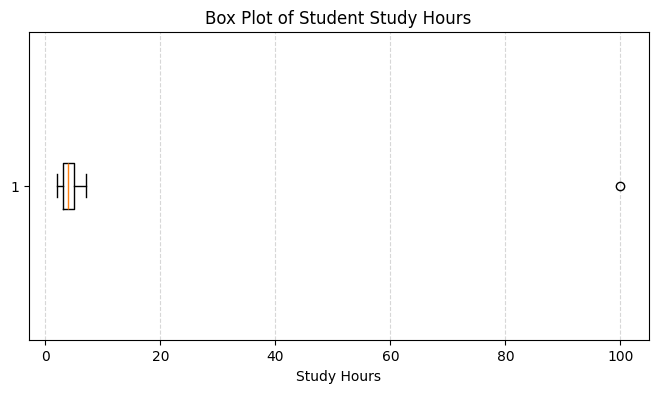

In [7]:

# Step 6: Visualize potential outliers using a box plot

plt.figure(figsize=(8, 4))

plt.boxplot(df["Study_Hours"], vert=False)

plt.title("Box Plot of Student Study Hours")
plt.xlabel("Study Hours")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.show()


In [8]:

# Step 7: Create the final analysis dataset

# Keep the detected outlier for documentation
outlier_records = outliers.copy()

# Exclude flagged records from this demonstration's analysis
df_clean = df.drop(index=outliers.index).copy()

print("Original rows after basic cleaning:", len(df))
print("Flagged outlier records:", len(outlier_records))
print("Rows in final analysis dataset:", len(df_clean))

print("\nFinal dataset:")
display(df_clean)


Original rows after basic cleaning: 14
Flagged outlier records: 1
Rows in final analysis dataset: 13

Final dataset:


,Student,Study_Hours,Attendance,Exam_Score
0,Asha,2.0,75.0,55.0
1,Rahul,4.0,85.0,75.0
2,Meera,3.0,80.0,65.0
3,Arjun,5.0,90.0,88.0
4,Diya,4.0,88.0,72.0
5,Kiran,6.0,83.5,90.0
6,Neha,2.0,70.0,50.0
7,Rohan,4.0,95.0,95.0
8,Anu,3.0,82.0,73.5
9,Vijay,5.0,85.0,80.0


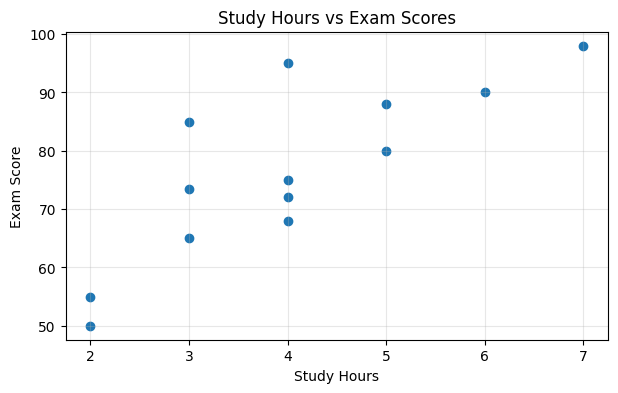

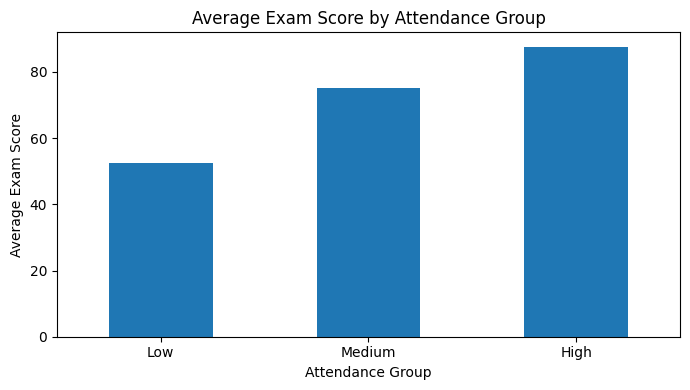

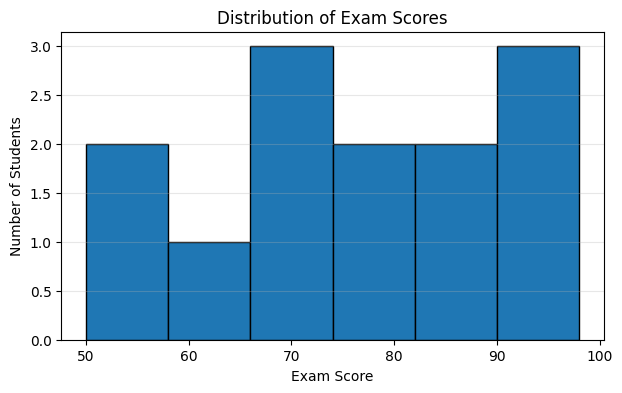

In [9]:

# Step 8: Visualize student performance

# Chart 1: Study hours vs exam scores
plt.figure(figsize=(7, 4))
plt.scatter(df_clean["Study_Hours"], df_clean["Exam_Score"])
plt.title("Study Hours vs Exam Scores")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.grid(True, alpha=0.3)
plt.show()

# Chart 2: Average exam score by attendance group
df_clean["Attendance_Group"] = pd.cut(
    df_clean["Attendance"],
    bins=[0, 75, 85, 100],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

average_scores = df_clean.groupby(
    "Attendance_Group", observed=False
)["Exam_Score"].mean()

plt.figure(figsize=(7, 4))
average_scores.plot(kind="bar")
plt.title("Average Exam Score by Attendance Group")
plt.xlabel("Attendance Group")
plt.ylabel("Average Exam Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Chart 3: Distribution of exam scores
plt.figure(figsize=(7, 4))
plt.hist(df_clean["Exam_Score"], bins=6, edgecolor="black")
plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.grid(axis="y", alpha=0.3)
plt.show()


In [10]:

# Step 9: Save the cleaned dataset

# Remove the temporary attendance group column
final_df = df_clean.drop(columns=["Attendance_Group"], errors="ignore")

# Save the cleaned data as a CSV file
final_df.to_csv("cleaned_student_performance.csv", index=False)

print("Cleaned dataset saved successfully!")
print("File: cleaned_student_performance.csv")
print("Final number of records:", len(final_df))

display(final_df.head())


Cleaned dataset saved successfully!
File: cleaned_student_performance.csv
Final number of records: 13


,Student,Study_Hours,Attendance,Exam_Score
0,Asha,2.0,75.0,55.0
1,Rahul,4.0,85.0,75.0
2,Meera,3.0,80.0,65.0
3,Arjun,5.0,90.0,88.0
4,Diya,4.0,88.0,72.0


In [11]:

# Step 10: Summarize the project results

print("=" * 45)
print("DATA CLEANING & VISUALIZATION REPORT")
print("=" * 45)

print("Original records:", len(df_raw))
print("Missing values in original data:", int(df_raw.isnull().sum().sum()))
print("Duplicate rows in original data:", int(df_raw.duplicated().sum()))
print("Potential outliers flagged:", len(outlier_records))
print("Records in final analysis:", len(final_df))

print("\nAverage exam score:", round(final_df["Exam_Score"].mean(), 2))
print("Highest exam score:", final_df["Exam_Score"].max())
print("Lowest exam score:", final_df["Exam_Score"].min())

print("\nProject completed successfully!")


DATA CLEANING & VISUALIZATION REPORT
Original records: 15
Missing values in original data: 3
Duplicate rows in original data: 1
Potential outliers flagged: 1
Records in final analysis: 13

Average exam score: 76.5
Highest exam score: 98.0
Lowest exam score: 50.0

Project completed successfully!
